Importar datos :D

In [70]:
import pandas as pd
import openpyxl
import numpy as np
import missingno as msno
from functools import reduce

In [49]:
df_1 = pd.read_excel("Totalizadores Planta - 2021_2023.xlsx", sheet_name=None)
df_2 = pd.read_excel("Totalizadores Planta 2020_2022.xlsx", sheet_name=None)
df_3 = pd.read_excel("Totalizadores Planta 2022_2023.xlsx", sheet_name=None)


In [149]:
archivos = {
    "2021_2023": df_1,
    "2020_2022": df_2,
    "2022_2023": df_3,
}

COL_FECHA = "fecha"

def limpiar(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip().str.lower()

    dia = pd.to_datetime(df["dia"], errors="coerce").dt.normalize()

    h = df["hora"]
    if pd.api.types.is_datetime64_any_dtype(h):
        h = h.dt.strftime("%H:%M:%S")
    hora = pd.to_timedelta(h.astype(str), errors="coerce")

    # quedarse solo con los cierres de día (23:30 en adelante)
    es_cierre = (hora >= pd.Timedelta(hours=23, minutes=30)) & (hora < pd.Timedelta(days=1))
    df = df[es_cierre].copy()

    # fijar la marca de tiempo en 23:59:00 exactos
    df[COL_FECHA] = dia[es_cierre].dt.date
    df = df.drop(columns=["dia", "hora"])
    return df.dropna(subset=[COL_FECHA])

def unir_hojas(dic):
    partes = []
    for hoja, df in dic.items():
        df = limpiar(df).set_index(COL_FECHA)
        n_antes = len(df)
        df = df.groupby(level=0).first()   # colapsa fechas repetidas dentro de la hoja
        if len(df) < n_antes:
            print(f"'{hoja}': {n_antes - len(df)} filas colapsadas por fecha repetida")
        partes.append(df)
    return reduce(lambda a, b: a.combine_first(b), partes)

def borrar_columnas_vacias(df, min = 1100):
    empty_columns = []
    for col in df.columns:
        a =df[col].isnull().sum() >= min
        if a:
            empty_columns.append(col)
            print(f"{col}")
    df.drop(columns=empty_columns, inplace=True)


tot_1 = unir_hojas(df_1)
tot_2 = unir_hojas(df_2)
tot_3 = unir_hojas(df_3)

df_total = (
    reduce(lambda a, b: a.combine_first(b), [tot_1, tot_2, tot_3])
    .sort_index()
    .reset_index()
)

print(df_total.shape)
print(df_total[COL_FECHA].is_unique)   # debe dar True

borrar_columnas_vacias(df_total)




'Consolidado KPI': 12 filas colapsadas por fecha repetida
'Consolidado Produccion': 12 filas colapsadas por fecha repetida
'Totalizadores Produccion': 12 filas colapsadas por fecha repetida
'Consolidado EE': 12 filas colapsadas por fecha repetida
'Totalizadores Energia': 12 filas colapsadas por fecha repetida
'Consolidado Agua': 12 filas colapsadas por fecha repetida
'Totalizadores Agua': 12 filas colapsadas por fecha repetida
'Consolidado GasVapor': 12 filas colapsadas por fecha repetida
'Totalizadores Gas y Vapor': 12 filas colapsadas por fecha repetida
'Consolidado Aire': 12 filas colapsadas por fecha repetida
'Totalizadores Aire': 12 filas colapsadas por fecha repetida
'Totalizadores CO2': 13 filas colapsadas por fecha repetida
'Totalizadores Efluentes': 12 filas colapsadas por fecha repetida
'Totalizadores Glicol': 12 filas colapsadas por fecha repetida
'Seguimiento Dia': 12 filas colapsadas por fecha repetida
'Auxiliar': 12 filas colapsadas por fecha repetida
'Consolidado KPI': 1

C:\Users\Arturo\AppData\Local\Temp\ipykernel_25528\3089719798.py:57: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()


In [144]:
df_total[df_total.duplicated("fecha",keep=False)] \
    .sort_values("fecha")

,fecha,ee planta / hl,ee elaboracion / hl,ee bodega / hl,ee cocina / hl,ee envasado / hl,ee linea 2 / hl,ee linea 3 / hl,ee linea 4 / hl,ee servicios / hl,...,.2,.5,vapor _vapor_l5 (kg),tot fermantacion_cocina,tot reposo inferior,tot reposo superior,id,hl session ipa,"tot l3, l4 y planta de co2",hl linea 2


<Axes: >

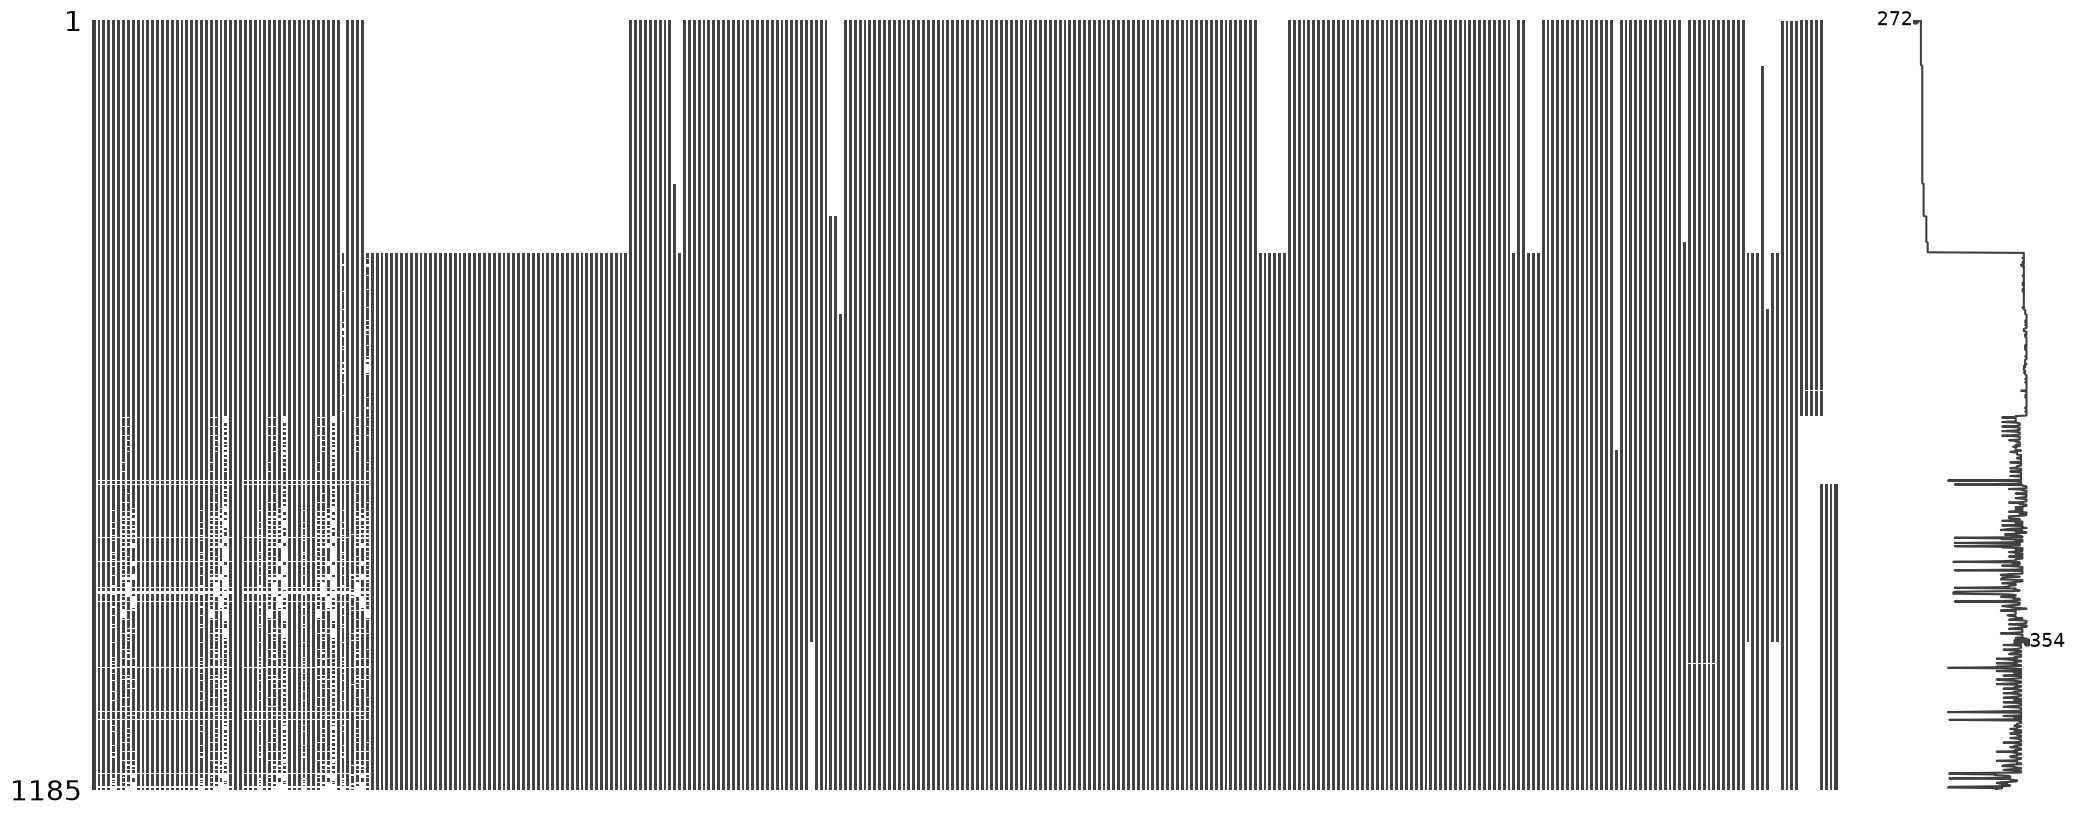

In [145]:
msno.matrix(df_total.sort_values("fecha"))

In [150]:
df_total.head()

,fecha,ee planta / hl,ee elaboracion / hl,ee bodega / hl,ee cocina / hl,ee envasado / hl,ee linea 2 / hl,ee linea 3 / hl,ee linea 4 / hl,ee servicios / hl,...,.2,.5,vapor _vapor_l5 (kg),tot fermantacion_cocina,tot reposo inferior,tot reposo superior,id,hl session ipa,"tot l3, l4 y planta de co2",hl linea 2
0,2020-07-01,642.727209,47.145349,69.023256,0.000000,13.813953,14.578784,0.000000,0.000000,554.604651,...,NaN,NaN,923.69,570.17,6323.06,0.1,10024.0,NaN,NaN,NaN
1,2020-07-02,7.767254,0.769609,0.798838,0.319229,2.358593,4.158962,1.506838,1.521823,5.429388,...,0.0,0.0,270.75,694.08,5349.47,0.8,10049.0,NaN,NaN,NaN
2,2020-07-03,8.801205,0.862593,0.835762,0.260924,1.985462,39.076667,1.448962,1.500923,5.703346,...,0.0,0.0,299.68,400.66,4965.47,0.5,10074.0,NaN,NaN,NaN
3,2020-07-04,5.175639,0.439225,0.371077,0.258048,1.442114,4.348182,1.355238,1.536507,3.058399,...,0.0,0.0,4046.11,447.89,5040.93,1.0,10099.0,NaN,NaN,NaN
4,2020-07-05,7.924665,0.802365,0.717787,0.301592,1.664726,5.125920,2.704348,1.471990,5.094301,...,0.0,0.0,5017.28,400.06,5690.25,0.2,10124.0,NaN,NaN,NaN


In [151]:
df_total.to_excel("df_total.xlsx")